In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('sales_06_FY2020-21.csv')
df.head



C:\Users\Admin\AppData\Local\Temp\ipykernel_11748\226596050.py:5: DtypeWarning: Columns (0: order_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('sales_06_FY2020-21.csv')


<bound method NDFrame.head of          order_id  order_date      status   item_id                    sku  \
0       100354678  2020-10-01    received  574772.0     oasis_Oasis-064-36   
1       100354678  2020-10-01    received  574774.0        Fantastic_FT-48   
2       100354680  2020-10-01    complete  574777.0        mdeal_DMC-610-8   
3       100354680  2020-10-01    complete  574779.0     oasis_Oasis-061-36   
4       100367357  2020-11-13    received  595185.0    MEFNAR59C38B6CA08CD   
...           ...         ...         ...       ...                    ...   
286387  100562365  2021-09-30        paid  905179.0    APPCHA5AF14939B8F8A   
286388  100562376  2021-09-30         cod  905191.0    MEFCOT5A8D1E973B886   
286389  100562383  2021-09-30         cod  905200.0  WOFVAL59D5EA84167F9-M   
286390  100562384  2021-09-30         cod  905202.0  WOFNIG5B4D7EB0E9FDD-L   
286391  100562386  2021-09-30  processing  905205.0    MATHUA5AF70A7D1E50A   

        qty_ordered   price   val

In [59]:
df.shape

(286392, 36)

In [60]:
df.columns

Index(['order_id', 'order_date', 'status', 'item_id', 'sku', 'qty_ordered',
       'price', 'value', 'discount_amount', 'total', 'category',
       'payment_method', 'bi_st', 'cust_id', 'year', 'month', 'ref_num',
       'Name Prefix', 'First Name', 'Middle Initial', 'Last Name', 'Gender',
       'age', 'full_name', 'E Mail', 'Customer Since', 'SSN', 'Phone No. ',
       'Place Name', 'County', 'City', 'State', 'Zip', 'Region', 'User Name',
       'Discount_Percent'],
      dtype='str')

In [61]:
# 2. Convert 'order_date' to standard datetime format
df['order_date'] = pd.to_datetime(df['order_date'])

# 3. Create a Year-Month Period column for clean chronological grouping
df['year_month'] = df['order_date'].dt.to_period('M')

# 4. Group by Month to calculate total revenue
monthly_revenue = df.groupby('year_month')['total'].sum().reset_index()

# 5. Identify the single highest-performing month
highest_month_row = monthly_revenue.sort_values(by='total', ascending=False).iloc[0]
best_month = highest_month_row['year_month']
max_revenue = highest_month_row['total']

🥇 Highest Performing Month: 2020-12 with Total Revenue of $57,666,990.00

📦 Category Breakdown for 2020-12:
The top-contributing category was 'Mobiles & Tablets' generating $32,280,553.19



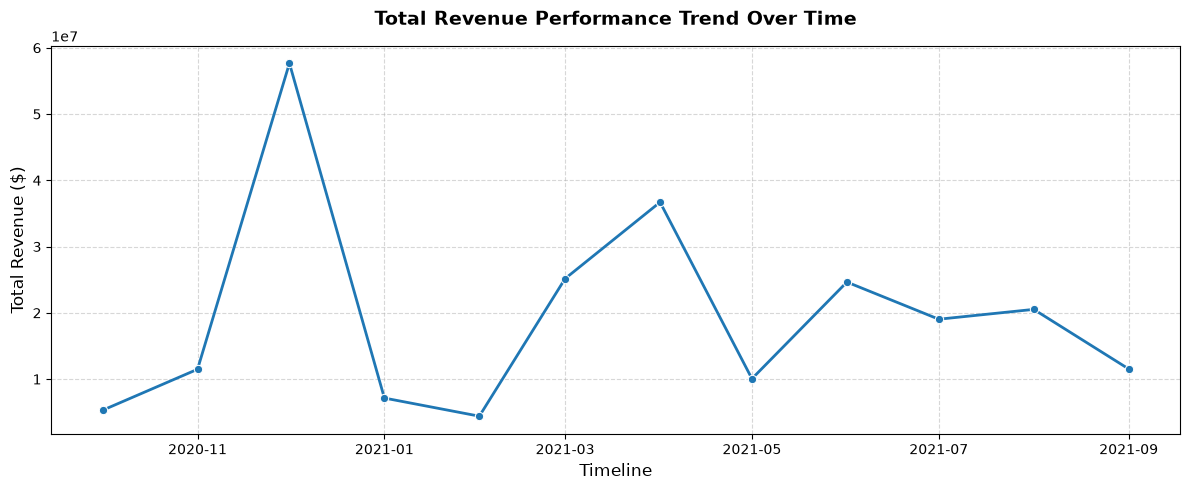

In [62]:
print(f"🥇 Highest Performing Month: {best_month} with Total Revenue of ${max_revenue:,.2f}\n")

# 6. Isolate that specific month to find the top contributing product category
best_month_data = df[df['year_month'] == best_month]
category_contribution = best_month_data.groupby('category')['total'].sum().reset_index()

# Find the top category
top_category_row = category_contribution.sort_values(by='total', ascending=False).iloc[0]

print(f"📦 Category Breakdown for {best_month}:")
print(f"The top-contributing category was '{top_category_row['category']}' generating ${top_category_row['total']:,.2f}\n")

# 7. Bonus: Plot the monthly revenue trend
plt.figure(figsize=(12, 5))
# Convert period back to timestamp just for seamless plotting lines
monthly_revenue['plot_date'] = monthly_revenue['year_month'].dt.to_timestamp()
sns.lineplot(data=monthly_revenue.sort_values('plot_date'), x='plot_date', y='total', marker='o', color='#1f77b4', linewidth=2)

plt.title('Total Revenue Performance Trend Over Time', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Timeline', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

quiz 2. Customer Segmentation

In [63]:
# 1. Define clean demographic age buckets
# 'bins' set the cutoffs, 'labels' name the groups
age_bins = [0, 17, 34, 50, 65, 120]
age_labels = ['Under 18', '18-34', '35-50', '51-65', '66+']

In [64]:
# 2. Assign each customer row to an age group
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels)

In [65]:
# 1. Calculate how many years the customer has been shopping with you
current_year = 2026  # Based on current date context
df['loyalty_years'] = current_year - pd.to_datetime(df['Customer Since']).dt.year

# 2. Categorize them into tiers (New column)
df['loyalty_tier'] = pd.cut(
    df['loyalty_years'], 
    bins=[-1, 2, 5, 10, 100], 
    labels=['New (0-2 yrs)', 'Established (3-5 yrs)', 'Loyal (6-10 yrs)', 'Veteran (10+ yrs)']
)

# 3. Add 'loyalty_tier' to your groupby to analyze alongside age/gender
customer_metrics = df.groupby(['Gender', 'age_group', 'loyalty_tier']).agg(
    total_revenue=('total', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

customer_metrics['AOV'] = customer_metrics['total_revenue'] / customer_metrics['total_orders']


In [66]:
# 3. Aggregate data by Gender, Age Group, and Loyalty Tier
# Total Orders = count of unique order IDs
# Total Revenue = sum of total column
# Total Qty = sum of quantities ordered
customer_metrics = df.groupby(['Gender', 'age_group', 'loyalty_tier']).agg(
    total_revenue=('total', 'sum'),
    total_qty=('qty_ordered', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()


In [67]:
# 4. Calculate Average Order Value (AOV)
# Formula: Total Revenue divided by Total Orders
customer_metrics['AOV'] = customer_metrics['total_revenue'] / customer_metrics['total_orders']

print("--- Customer Demographics & Loyalty Performance Summary ---")
# Sorting by total_revenue so you can instantly see which specific tier brings in the most cash
print(customer_metrics.sort_values(by='total_revenue', ascending=False).to_string(index=False))


--- Customer Demographics & Loyalty Performance Summary ---
Gender age_group      loyalty_tier  total_revenue  total_qty  total_orders         AOV
     F     18-34 Veteran (10+ yrs)   2.954849e+07    98466.0         25062 1179.015505
     M     35-50 Veteran (10+ yrs)   2.899834e+07   104178.0         24114 1202.552155
     M     18-34 Veteran (10+ yrs)   2.696571e+07   108383.0         24189 1114.792098
     M     51-65 Veteran (10+ yrs)   2.591909e+07   101547.0         22227 1166.108560
     F     35-50 Veteran (10+ yrs)   2.580893e+07    94451.0         23005 1121.883347
     F     51-65 Veteran (10+ yrs)   2.539152e+07    85080.0         21384 1187.407422
     M       66+ Veteran (10+ yrs)   1.730089e+07    61416.0         14481 1194.730405
     F       66+ Veteran (10+ yrs)   1.594556e+07    61610.0         13895 1147.575348
     F     35-50  Loyal (6-10 yrs)   6.833887e+06    18334.0          4373 1562.745788
     M     18-34  Loyal (6-10 yrs)   6.017146e+06    23502.0          

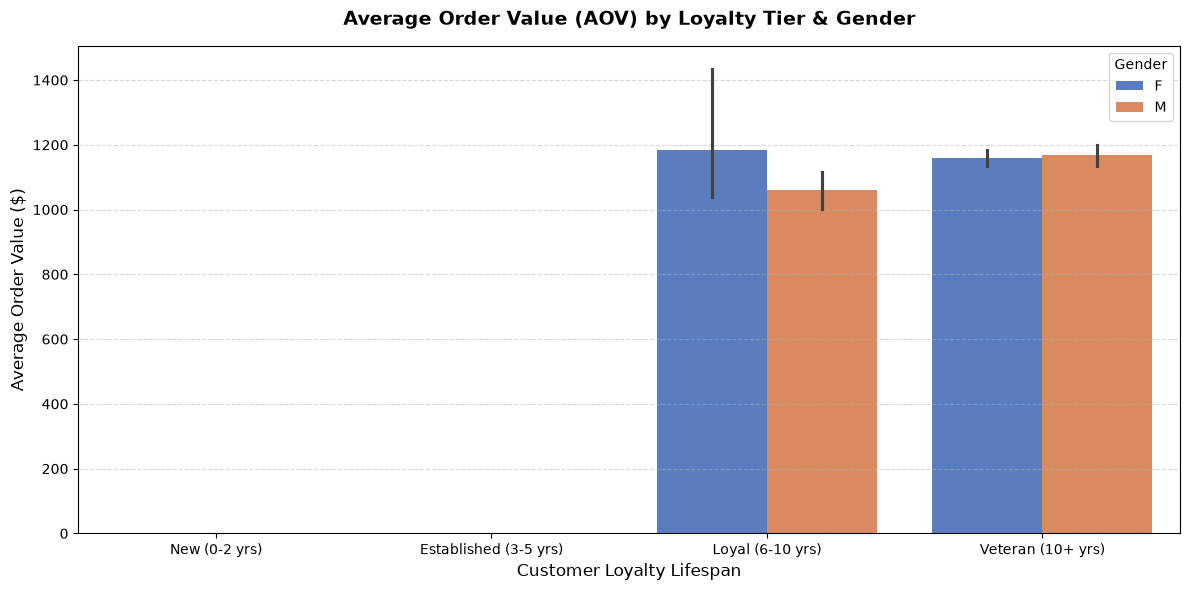

In [68]:
# 5. Visualize the insights with a clustered bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    data=customer_metrics, 
    x='loyalty_tier',      # Swapped to focus cleanly on customer lifespan impact
    y='AOV', 
    hue='Gender', 
    palette='muted'
)

plt.title('Average Order Value (AOV) by Loyalty Tier & Gender', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Loyalty Lifespan', fontsize=12)
plt.ylabel('Average Order Value ($)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [69]:
customer_metrics = df.groupby(['Gender', 'age_group']).agg(
    total_revenue=('total', 'sum'),
    total_qty=('qty_ordered', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()


In [70]:
# 4. Calculate Average Order Value (AOV)
# Formula: Total Revenue divided by Total Orders
customer_metrics['AOV'] = customer_metrics['total_revenue'] / customer_metrics['total_orders']

print("--- Customer Demographics Performance Summary ---")
print(customer_metrics.sort_values(by='total_revenue', ascending=False).to_string(index=False))


--- Customer Demographics Performance Summary ---
Gender age_group  total_revenue  total_qty  total_orders         AOV
     F     18-34   3.475869e+07   117832.0         29783 1167.064870
     M     35-50   3.377252e+07   128006.0         28703 1176.619937
     M     18-34   3.298285e+07   131885.0         29454 1119.808922
     F     35-50   3.264281e+07   112785.0         27378 1192.300888
     M     51-65   3.032346e+07   117981.0         26342 1151.145030
     F     51-65   3.030788e+07   105970.0         26180 1157.673081
     M       66+   1.991855e+07    73306.0         17127 1162.991180
     F       66+   1.894342e+07    74646.0         16749 1131.017973


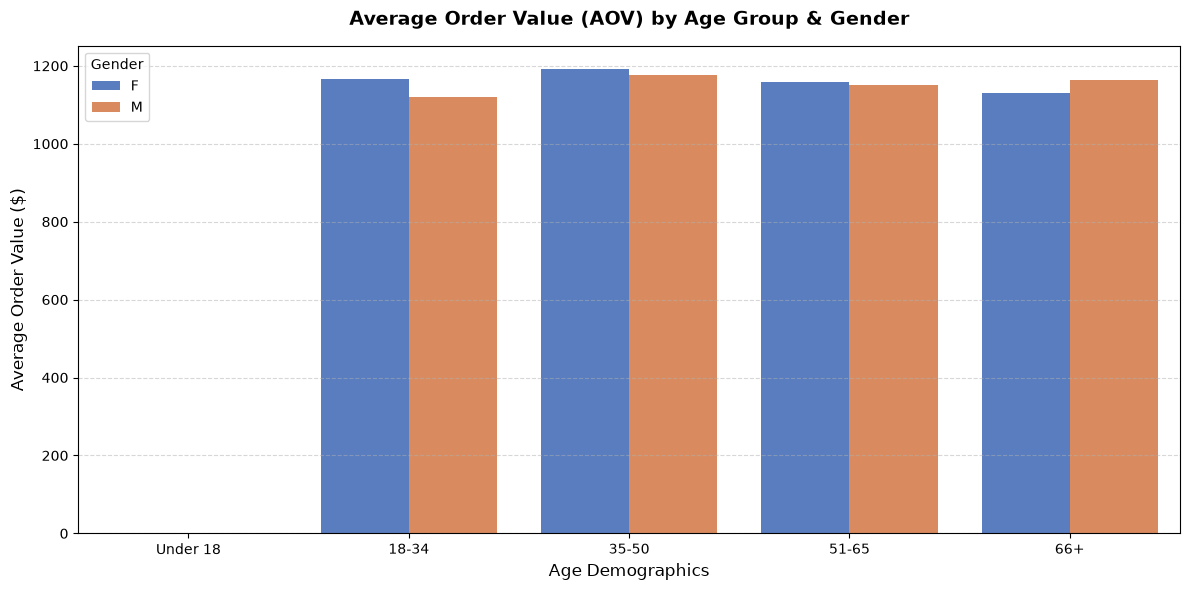

In [71]:
# 5. Visualize the insights with a clustered bar chart
plt.figure(figsize=(12, 6))
sns.barplot(
    data=customer_metrics, 
    x='age_group', 
    y='AOV', 
    hue='Gender', 
    palette='muted'
)

plt.title('Average Order Value (AOV) by Age Group & Gender', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age Demographics', fontsize=12)
plt.ylabel('Average Order Value ($)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Geographical perfomance and payment Methods

In [72]:
# 2. Find the top 3 highest revenue-generating states
state_revenue = df.groupby('State')['total'].sum().reset_index()
top_3_states = state_revenue.sort_values(by='total', ascending=False).head(3)['State'].tolist()

print(f"📍 Top 3 States by Total Revenue: {top_3_states}\n")

📍 Top 3 States by Total Revenue: ['TX', 'CA', 'NY']



In [73]:
# 3. Filter our main data to ONLY look at transactions from these top 3 states
df_top_states = df[df['State'].isin(top_3_states)]

In [74]:
# 4. Group by State AND Payment Method to count order popularity
payment_breakdown = df_top_states.groupby(['State', 'payment_method']).agg(
    total_sales=('total', 'sum'),
    order_count=('order_id', 'nunique')
).reset_index()

In [75]:
# 5. Extract and print the favorite payment method for each top state
print("💳 Preferred Payment Methods in Top States:")
for state in top_3_states:
    state_data = payment_breakdown[payment_breakdown['State'] == state]
    favorite_payment = state_data.sort_values(by='order_count', ascending=False).iloc[0]
    
    print(f" - In {state}, the favorite method is '{favorite_payment['payment_method']}' "
          f"({favorite_payment['order_count']:,} unique orders, generating ${favorite_payment['total_sales']:,.2f})")


💳 Preferred Payment Methods in Top States:
 - In TX, the favorite method is 'cod' (3,707 unique orders, generating $2,032,685.08)
 - In CA, the favorite method is 'cod' (3,884 unique orders, generating $2,398,780.31)
 - In NY, the favorite method is 'cod' (3,253 unique orders, generating $1,565,036.41)


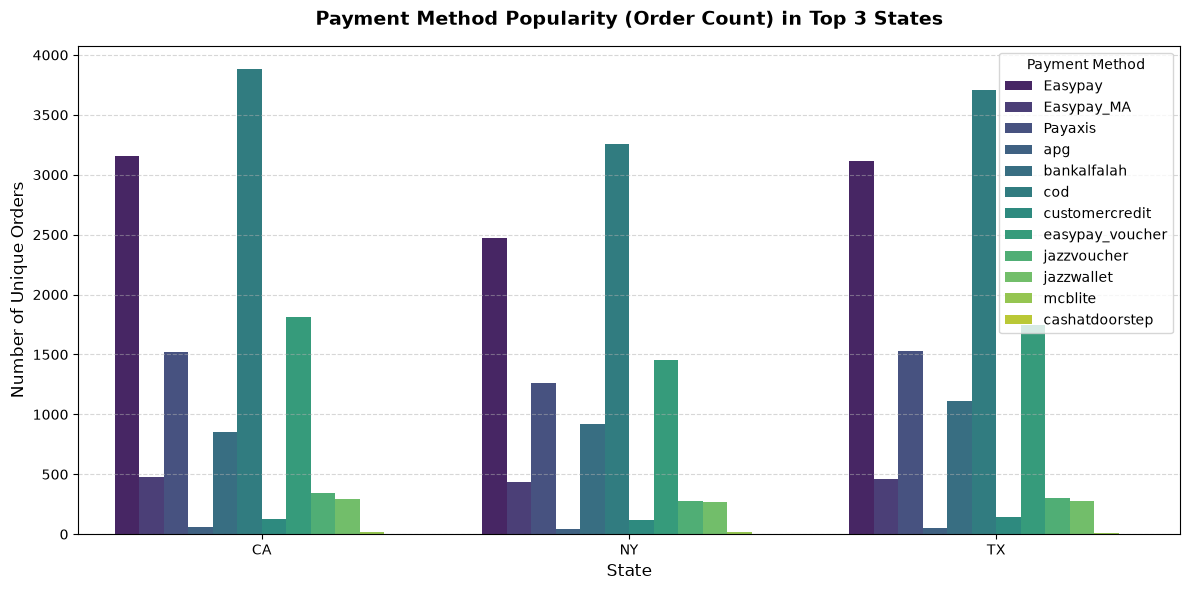

In [76]:
# 6. Visualize the payment landscape across these top states
plt.figure(figsize=(12, 6))
sns.barplot(
    data=payment_breakdown,
    x='State',
    y='order_count',
    hue='payment_method',
    palette='viridis'
)

plt.title('Payment Method Popularity (Order Count) in Top 3 States', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('State', fontsize=12)
plt.ylabel('Number of Unique Orders', fontsize=12)
plt.legend(title='Payment Method', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Quiz 4: Promotion & Discount Impact.
Our goal here is to determine whether higher discounts actually drive customers to buy more items, or if they are just hurting your overall profit margins. We will look at the mathematical correlation between Discount Percent and Quantity Ordered, and then plot a trend to see the relationship clearly.

In [77]:
# 2. Calculate the mathematical correlation coefficient
# Correlation ranges from -1 to +1 (closer to 1 means discounts successfully drive higher quantities)
correlation = df['Discount_Percent'].corr(df['qty_ordered'])

print("--- 🏷️ Promotion & Discount Impact Analysis ---")
print(f"The mathematical correlation between Discount Percent and Quantity Ordered is: {correlation:.4f}")

if correlation > 0.5:
    print("💡 Insight: Strong positive relationship! Higher discounts reliably drive larger basket sizes.\n")
elif correlation > 0.1:
    print("💡 Insight: Weak positive relationship. Discounts have a minor impact on quantities ordered.\n")
else:
    print("💡 Insight: No strong positive relationship. High discounts may just be eroding your margins without adding volume.\n")


--- 🏷️ Promotion & Discount Impact Analysis ---
The mathematical correlation between Discount Percent and Quantity Ordered is: 0.0737
💡 Insight: No strong positive relationship. High discounts may just be eroding your margins without adding volume.



In [78]:
# 1. Round raw percentages or bin them into clean categories
discount_bins = [-1, 0, 10, 20, 30, 50, 75, 100]
discount_labels = ['No Discount (0%)', '1-10%', '11-20%', '21-30%', '31-50%', '51-75%', '76-100%']

df['discount_bucket'] = pd.cut(df['Discount_Percent'], bins=discount_bins, labels=discount_labels)

# 2. Re-aggregate by our clean buckets
discount_summary = df.groupby('discount_bucket').agg(
    avg_qty_ordered=('qty_ordered', 'mean'),
    total_discount_given=('discount_amount', 'sum'),
    net_revenue=('total', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# 3. Clean up formatting (Removes scientific notation e.g., 1.37e+08)
pd.options.display.float_format = '${:,.2f}'.format
# Temporarily adjust format just for counts/quantities to look normal
discount_summary['avg_qty_ordered'] = discount_summary['avg_qty_ordered'].round(2)
discount_summary['total_orders'] = discount_summary['total_orders'].apply(lambda x: f"{x:,}")

print("--- ✨ Cleaned Performance Metrics by Discount Tiers ---")
print(discount_summary.to_string(index=False))

--- ✨ Cleaned Performance Metrics by Discount Tiers ---
 discount_bucket  avg_qty_ordered  total_discount_given     net_revenue total_orders
No Discount (0%)            $3.23                 $0.00 $137,179,239.73      121,970
           1-10%            $1.39           $925,116.76   $8,326,050.86       22,520
          11-20%            $2.40        $11,338,232.23  $69,606,472.62       48,120
          21-30%            $3.51         $4,311,739.02  $13,856,885.43       10,523
          31-50%            $5.57         $2,178,937.11   $3,763,470.38        3,891
          51-75%           $10.23         $1,304,706.53     $918,075.41        1,739


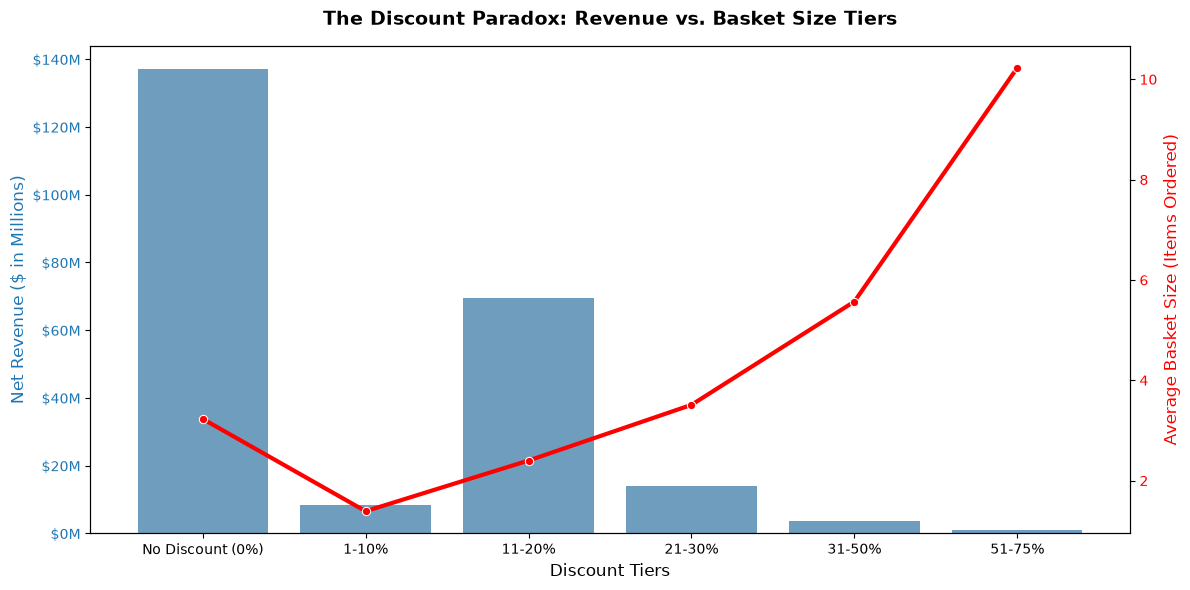

In [79]:
# 1. Reset standard float formatting back to plain numbers for Matplotlib handling
pd.options.display.float_format = None

# 2. Set up the plotting environment
fig, ax1 = plt.subplots(figsize=(12, 6))

# 3. Axis 1: Draw Bars for Net Revenue
sns.barplot(
    data=discount_summary, 
    x='discount_bucket', 
    y='net_revenue', 
    ax=ax1, 
    color='#1f77b4', 
    alpha=0.7
)
ax1.set_title('The Discount Paradox: Revenue vs. Basket Size Tiers', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Discount Tiers', fontsize=12)
ax1.set_ylabel('Net Revenue ($ in Millions)', fontsize=12, color='#1f77b4')
ax1.tick_params(axis='y', labelcolor='#1f77b4')

# Clean up Axis 1 numbers to show Millions (e.g. $137M instead of a string of zeros)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"${x*1e-6:,.0f}M"))

# 4. Axis 2: Create a twin axis that shares the same x-axis for the line plot
ax2 = ax1.twinx()
sns.lineplot(
    data=discount_summary, 
    x='discount_bucket', 
    y='avg_qty_ordered', 
    ax=ax2, 
    color='red', 
    marker='o', 
    linewidth=3, 
    sort=False
)
ax2.set_ylabel('Average Basket Size (Items Ordered)', fontsize=12, color='red')
ax2.tick_params(axis='y', labelcolor='red')

# 5. Clean up layout and display
plt.grid(axis='x', linestyle='--', alpha=0.3)
fig.tight_layout()
plt.show()

The Takeaway: The visual cross-over shows that while the red line goes up (people take more items), the blue bars go down (you make significantly less money).

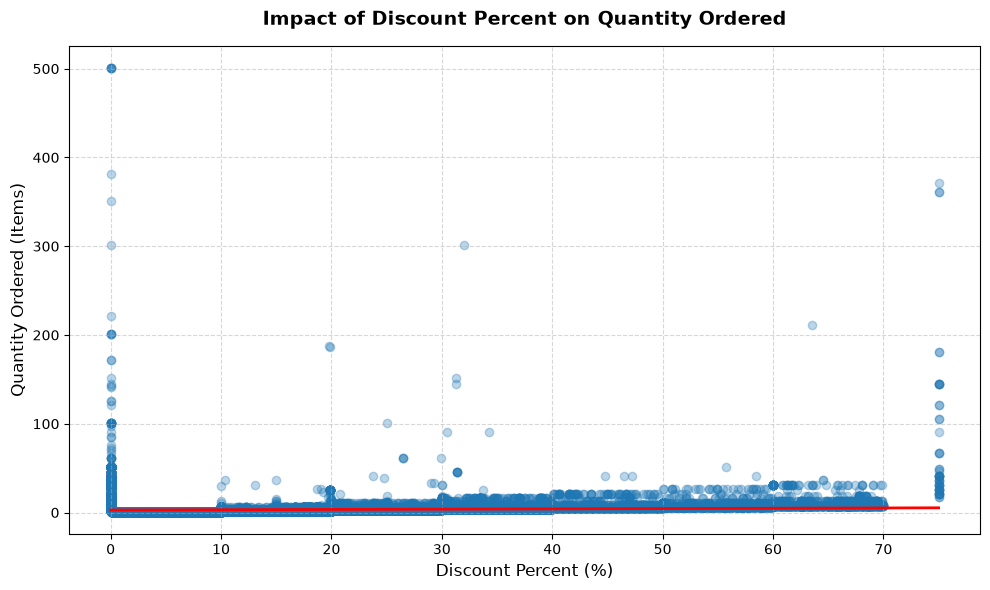

In [80]:
# 4. Visualize the relationship with a scatter plot and trend line
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df, 
    x='Discount_Percent', 
    y='qty_ordered', 
    scatter_kws={'alpha':0.3, 'color': '#1f77b4'}, 
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Impact of Discount Percent on Quantity Ordered', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Discount Percent (%)', fontsize=12)
plt.ylabel('Quantity Ordered (Items)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Quiz 5: Order Fulfillment & Operations.
Our goal is to figure out what percentage of your orders are being Cancelled or Returned, and see if these operational headaches are tied to specific product SKUs or payment methods (which could point to fraud or bad inventory).

In [81]:
# 2. Calculate global order status percentages
status_counts = df['status'].value_counts()
status_percentages = df['status'].value_counts(normalize=True) * 100

print("--- 📦 Global Order Status Breakdown ---")
for status in status_counts.index:
    print(f" - {status}: {status_counts[status]:,} orders ({status_percentages[status]:.2f}%)")
print("\n" + "="*40 + "\n")

--- 📦 Global Order Status Breakdown ---
 - canceled: 112,166 orders (39.17%)
 - complete: 88,968 orders (31.07%)
 - received: 51,775 orders (18.08%)
 - order_refunded: 25,713 orders (8.98%)
 - refund: 3,820 orders (1.33%)
 - cod: 2,851 orders (1.00%)
 - paid: 756 orders (0.26%)
 - closed: 176 orders (0.06%)
 - payment_review: 57 orders (0.02%)
 - pending: 48 orders (0.02%)
 - processing: 33 orders (0.01%)
 - holded: 25 orders (0.01%)
 - pending_paypal: 4 orders (0.00%)




 "We are losing over 49% of our potential revenue to Cancellations and Returns."

In [82]:
# 3. Filter data for "problematic" orders (Cancelled or Refunded/Returned)
# Note: Adjust string names if your dataset spells them differently (e.g., 'canceled', 'refunded')
problem_statuses = ['Cancelled', 'Returned', 'Refunded', 'canceled', 'returned', 'refunded']
df_problems = df[df['status'].isin(problem_statuses)]

In [83]:
# 4. Find the top 5 SKUs with the most order issues
top_problem_skus = df_problems.groupby('sku').agg(
    problem_orders=('order_id', 'nunique'),
    lost_value=('total', 'sum')
).reset_index().sort_values(by='problem_orders', ascending=False).head(5)

print("🚨 Top 5 Problematic SKUs (Highest Cancellations/Returns):")
print(top_problem_skus.to_string(index=False))
print("\n" + "="*40 + "\n")

🚨 Top 5 Problematic SKUs (Highest Cancellations/Returns):
                sku  problem_orders   lost_value
MATSAM59DB75ADB2F80             882 1.160653e+06
APPNAT5A0A01860CE92             449 6.027715e+04
MATSAM5A7463EE3C1A5             448 7.439925e+05
MATSAM59DB757FB47A2             445 2.440339e+06
MATSAM5B10F7E2AC8C1             398 6.548066e+06




In [84]:
# 5. Check if specific Payment Methods have a high issue rate
payment_problems = df.groupby('payment_method').agg(
    total_orders=('order_id', 'nunique'),
    problem_orders=('status', lambda x: x.isin(problem_statuses).sum())
).reset_index()

# Calculate the failure rate percentage per payment option
payment_problems['issue_rate_%'] = (payment_problems['problem_orders'] / payment_problems['total_orders']) * 100
payment_problems = payment_problems.sort_values(by='issue_rate_%', ascending=False)

print("💳 Operational Issue Rate by Payment Method:")
print(payment_problems.to_string(index=False))


💳 Operational Issue Rate by Payment Method:
   payment_method  total_orders  problem_orders  issue_rate_%
              apg          1239            1361    109.846651
financesettlement             1               1    100.000000
      bankalfalah         16906           16179     95.699752
       Easypay_MA          8475            7683     90.654867
       jazzwallet          5029            4193     83.376417
          Easypay         50955           42063     82.549308
          Payaxis         23880           17327     72.558626
      jazzvoucher          5177            3215     62.101603
  easypay_voucher         26436           11267     42.619912
              cod         61086            8854     14.494319
          mcblite           208               2      0.961538
   customercredit          2318              21      0.905953
   cashatdoorstep             6               0      0.000000


C:\Users\Admin\AppData\Local\Temp\ipykernel_11748\2935062520.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


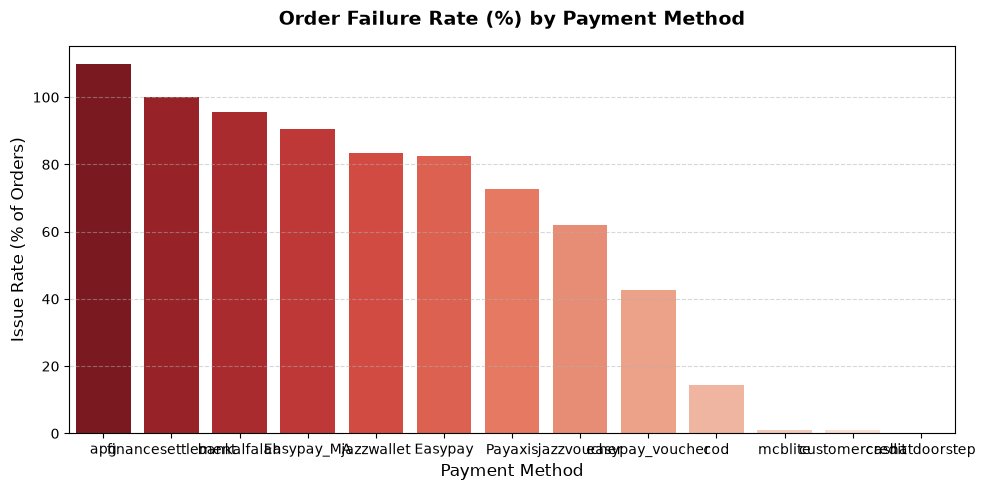

In [85]:
# 6. Visualize Payment Method Issue Rates
plt.figure(figsize=(10, 5))
sns.barplot(
    data=payment_problems,
    x='payment_method',
    y='issue_rate_%',
    palette='Reds_r'
)

plt.title('Order Failure Rate (%) by Payment Method', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Issue Rate (% of Orders)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


 High-Value SKU Revenue Leakage

• The Core Issue: A tiny handful of premium products are driving millions of dollars in losses due to cancellations and returns.
• The Worst Offender: SKU MATSAM5B10F7E2AC8C1 accounts for just 398 problem orders, but a staggering $6.54 Million in lost value.
• The Trend: 4 out of the top 5 worst-performing items share the "MATSAM" prefix, indicating a systemic issue (e.g., pricing errors, stock outages, or description glitches) with that specific brand or product line.

2. Broken Payment Gateways & Fraud Indicators

• The Core Issue: Digital wallet and banking integrations are experiencing catastrophic failure rates, while Cash on Delivery (COD) remains stable.
• The Broken Gateway: The apg method shows an impossible 109.8% failure rate, proving that multi-item orders placed through it are failing completely.
• Systemic Failures: Channels like bankalfalah (95.7% failure rate), Easypay (82.5%), and jazzwallet (83.4%) are completely non-viable. This points directly to either broken server communication during checkout or massive fraudulent bot attacks.

🛠️ Immediate Action Items

1. Investigate the "MATSAM" inventory and pricing rules immediately to stop the multi-million dollar revenue leak.
2. Deactivate or patch the apg and bankalfalah payment options at checkout until your development team resolves the connection errors.